# Christian Eriksen: beyond goals and assists

Expected goals and assists, shooting, ball security and a full percentile profile, for every Premier League
midfielder with 6,000+ minutes over Eriksen's six full Spurs seasons (2013/14 to 2018/19). Opta's expected goals (xG)
and expected assists (xA) as published by the Premier League's stats API.

Charts 5, 6, 8 and 9 of the report.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
EXT = ROOT / "data" / "external"
DARK_THEME = os.environ.get("REPORT_THEME") == "dark"  # dark = black-background charts for the PDF; the README uses the light ones
FIGS = ROOT / "reports" / ("figures_dark" if DARK_THEME else "figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Spurs navy for Eriksen, a lighter navy for secondary series
SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#7A8BB8", "#132257", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
BG, GRID, SPAN, HEAT, HEAT_HI = "white", "#ECEAE4", "#FBF3DC", [NAVY, SKY, "#E8F1FA", "#FFFFFF"], "white"
if DARK_THEME:  # Spurs navy page: Eriksen in white, others in muted navy
    SKY, NAVY, GREY, DARK, MUTED = "#8C9CC8", "#FFFFFF", "#4A5888", "#FFFFFF", "#B8C0D9"
    BG, GRID, SPAN, HEAT, HEAT_HI = "#132257", "#25356F", "#2A2F5A", ["#FFFFFF", "#8C9CC8", "#2A3B78", "#0D1840"], "#000000"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad, 2010/11 to 2019/20"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Anton (headlines) and Lato (text), bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Lato", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": DARK, "legend.labelcolor": DARK,
})


def fs(light, pdf):
    """Figure size: the README (light) size, or a narrower one for the PDF so the text prints larger on the page."""
    return pdf if DARK_THEME else light


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=18, color=DARK, family="Anton")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2011 -> '2011/12'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2019/20 (official Opta stats). Season = starting year."""
    d = pd.concat([pd.read_csv(EXT / "pl_midfielders_2010-2018.csv"), pd.read_csv(EXT / "pl_midfielders_2018-2020.csv")])
    d = d.drop_duplicates(["season", "id"])
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["through"] = p90(d.throughBalls)                          # through balls per 90
    d["box"] = p90(d.totalTouchesInOppositionBox)               # touches in the opposition box per 90
    d["dribbles"] = d.successfulDribbles + d.unsuccessfulDribbles
    d["dribble_pct"] = d.successfulDribbles / d.dribbles.where(d.dribbles > 0)
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
ERIKSEN, SILVA = "Christian Eriksen", "David Silva"
SPURS = range(2013, 2019)   # his six full Spurs seasons, 2013/14 to 2018/19 (he left in January 2020)
FINISH = {2013: "6th", 2014: "5th", 2015: "3rd", 2016: "2nd", 2017: "3rd", 2018: "4th", 2019: "6th"}  # Spurs league finish

In [2]:
D = load_opta()
E = D[(D.name == ERIKSEN) & D.season.isin(SPURS)].sort_values("season")
W = D[D.season.isin(SPURS)]
T = W.groupby("name").agg(g=("goals", "sum"), pen=("penaltyGoals", "sum"), xg=("expectedGoals", "sum"), a=("goalAssists", "sum"),
                          xa=("expectedAssists", "sum"), sh=("totalShots", "sum"), m=("timePlayed", "sum"),
                          loss=("totalLossesOfPossession", "sum"), cc=("keyPassesAttemptAssists", "sum"), thr=("throughBalls", "sum"),
                          pas=("totalPasses", "sum"), unp=("totalUnsuccessfulPassesExclCrossesAndCorners", "sum"),
                          lp=("successfulLongPasses", "sum"), opp=("successfulPassesOppositionHalf", "sum"),
                          drb=("successfulDribbles", "sum"), rec=("recoveries", "sum"), tk=("tacklesWon", "sum"), it=("interceptions", "sum"))
T = T[T.m >= 6000].copy()
p90 = lambda c: T[c] / T.m * 90
T["npg90"] = (T.g - T.pen) / T.m * 90; T["sh90"] = p90("sh"); T["xgps"] = T.xg / T.sh; T["a90"] = p90("a"); T["xa90"] = p90("xa")
T["cc90"] = p90("cc"); T["thr90"] = p90("thr"); T["opp90"] = p90("opp"); T["lp90"] = p90("lp"); T["pct"] = 1 - T.unp / T.pas
T["drb90"] = p90("drb"); T["rec90"] = p90("rec"); T["def90"] = (T.tk + T.it) / T.m * 90; T["loss90"] = p90("loss")
T["over_g"] = T.g - T.xg; T["over_a"] = T.a - T.xa
for c in ["over_a", "over_g", "sh90", "loss90"]:
    print(c, T[c].sort_values(ascending=False).head(4).round(2).to_dict())
T.loc[[ERIKSEN, SILVA], ["g", "xg", "a", "xa", "sh", "sh90", "xgps", "loss90", "pct"]].round(3)

over_a {'Christian Eriksen': 16.98, 'Dele Alli': 14.22, 'Aaron Ramsey': 10.93, 'Kevin De Bruyne': 10.02}
over_g {'Eden Hazard': 22.83, 'Yaya Touré': 13.99, 'Juan Mata': 10.31, 'Gylfi Sigurdsson': 9.49}
sh90 {'Philippe Coutinho': 2.55, 'Paul Pogba': 2.31, 'Kevin Mirallas': 2.09, 'Charlie Adam': 2.04}
loss90 {'Marc Albrighton': 23.76, 'Kevin De Bruyne': 22.55, 'Charlie Adam': 22.28, 'Robbie Brady': 21.11}


,g,xg,a,xa,sh,sh90,xgps,loss90,pct
name,,,,,,,,,
Christian Eriksen,49,40.131,60,43.020,369,1.938,0.109,20.635,0.814
David Silva,40,39.010,53,49.893,202,1.277,0.193,16.007,0.875


## Charts

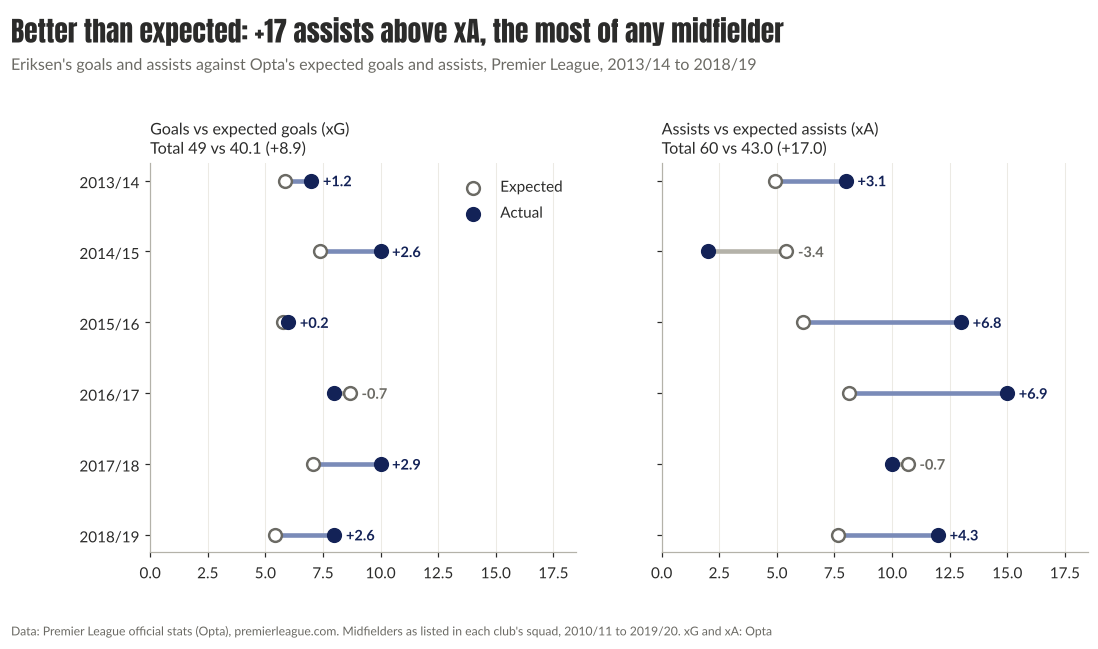

In [3]:
# Figure 5: goals and assists against expected, season by season
fig, axes = plt.subplots(1, 2, figsize=fs((11, 4.6), (9.6, 4.4)), sharey=True)
y = np.arange(len(E))[::-1]
for ax, (act, exp, lab) in zip(axes, [("goals", "expectedGoals", "Goals vs expected goals (xG)"), ("goalAssists", "expectedAssists", "Assists vs expected assists (xA)")]):
    for yi, r in zip(y, E.itertuples()):
        a, x = getattr(r, act), getattr(r, exp)
        ax.plot([x, a], [yi, yi], color=SKY if a >= x else GREY, lw=3, zorder=1, solid_capstyle="round")
        ax.text(max(a, x) + 0.5, yi, f"{a - x:+.1f}", va="center", fontsize=9.5, color=NAVY if a >= x else MUTED, fontweight="bold")
    ax.scatter(E[exp], y, s=70, color=BG, edgecolors=MUTED, lw=1.6, zorder=2, label="Expected")
    ax.scatter(E[act], y, s=80, color=NAVY, zorder=3, label="Actual")
    tot_a, tot_x = E[act].sum(), E[exp].sum()
    ax.set_title(f"{lab}\nTotal {tot_a} vs {tot_x:.1f} ({tot_a - tot_x:+.1f})", loc="left", fontsize=10.5, color=DARK)
    ax.set_xlim(0, 18.5); ax.grid(axis="x", color=GRID, lw=0.7); ax.set_axisbelow(True)
axes[0].set_yticks(y, [season_label(s) for s in E.season]); axes[0].legend(frameon=False, loc="upper right")
r = T.loc[ERIKSEN]
titles(fig, f"Better than expected: {r.over_a:+.0f} assists above xA, the most of any midfielder",
       "Eriksen's goals and assists against Opta's expected goals and assists, Premier League, 2013/14 to 2018/19", SRC_PL + ". xG and xA: Opta", y=1.1)
fig.savefig(FIGS / "05_beating_expected.png")

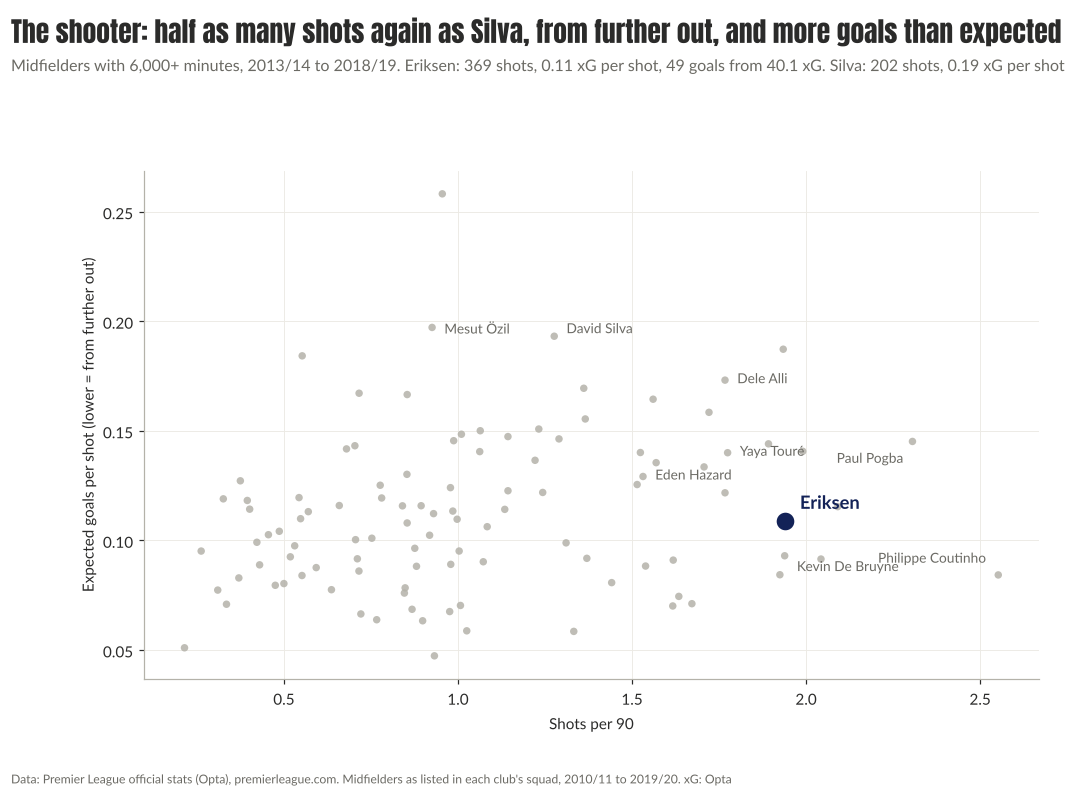

In [4]:
# Figure 6: the shooter
fig, ax = plt.subplots(figsize=fs((10.5, 6), (9, 5.8)))
o = T.drop([ERIKSEN]); ax.scatter(o.sh90, o.xgps, s=24, color=GREY, alpha=0.85, edgecolors="none")
ax.scatter(r.sh90, r.xgps, s=170, color=NAVY, edgecolors=BG, lw=1.5, zorder=3)
ax.annotate("Eriksen", (r.sh90, r.xgps), xytext=(10, 8), textcoords="offset points", color=NAVY, fontsize=12, fontweight="bold")
for n, (dx, dy) in {"David Silva": (8, 2), "Mesut Özil": (8, -4), "Philippe Coutinho": (-8, 8), "Paul Pogba": (-6, -14), "Eden Hazard": (8, -2),
                    "Kevin De Bruyne": (8, -10), "Dele Alli": (8, -2), "Yaya Touré": (8, -2)}.items():
    if n in T.index:
        ax.annotate(n, (T.loc[n].sh90, T.loc[n].xgps), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=MUTED,
                    ha="right" if dx < 0 else "left")
ax.set_xlabel("Shots per 90"); ax.set_ylabel("Expected goals per shot (lower = from further out)")
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
s = T.loc[SILVA]
titles(fig, "The shooter: half as many shots again as Silva, from further out, and more goals than expected",
       f"Midfielders with 6,000+ minutes, 2013/14 to 2018/19. Eriksen: {int(r.sh)} shots, {r.xgps:.2f} xG per shot, {int(r.g)} goals from {r.xg:.1f} xG. Silva: {int(s.sh)} shots, {s.xgps:.2f} xG per shot",
       SRC_PL + ". xG: Opta")
fig.savefig(FIGS / "06_shooting.png")

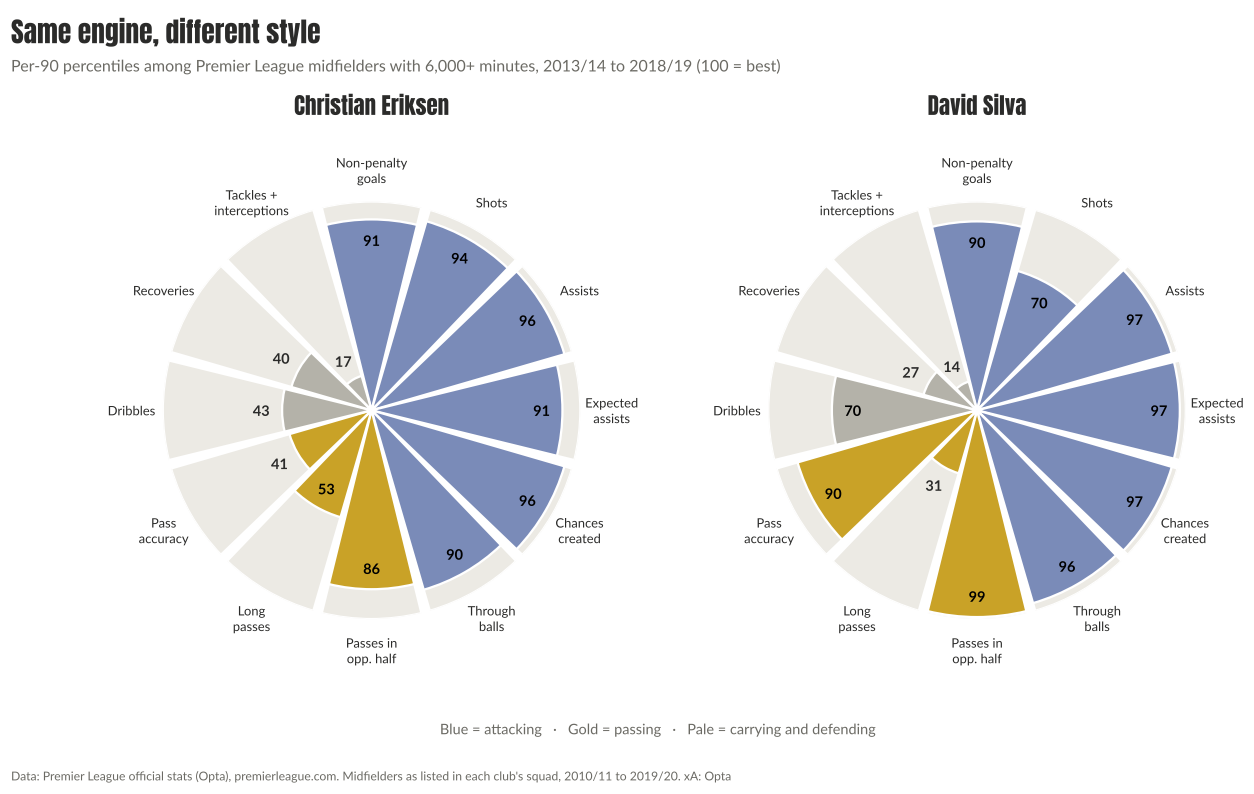

In [5]:
# Figure 8: two pizzas, Eriksen and Silva (percentiles among midfielders with 6,000+ minutes)
MET = [("npg90", "Non-penalty\ngoals"), ("sh90", "Shots"), ("a90", "Assists"), ("xa90", "Expected\nassists"), ("cc90", "Chances\ncreated"),
       ("thr90", "Through\nballs"), ("opp90", "Passes in\nopp. half"), ("lp90", "Long\npasses"), ("pct", "Pass\naccuracy"),
       ("drb90", "Dribbles"), ("rec90", "Recoveries"), ("def90", "Tackles +\ninterceptions")]
PCT = T[[m for m, _ in MET]].rank(pct=True) * 100
GROUPS = [SKY] * 6 + [GOLD] * 3 + [MUTED if DARK_THEME else GREY] * 3        # attacking, passing, defending/carrying
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), subplot_kw={"projection": "polar"})
fig.subplots_adjust(wspace=0.45)
ang = np.linspace(0, 2 * np.pi, len(MET), endpoint=False); wdt = 2 * np.pi / len(MET) * 0.92
for ax, n in zip(axes, [ERIKSEN, SILVA]):
    v = PCT.loc[n].values
    ax.bar(ang, [100] * len(MET), width=wdt, color=GRID, edgecolor=BG, lw=1.5, zorder=1)
    ax.bar(ang, v, width=wdt, color=GROUPS, edgecolor=BG, lw=1.5, zorder=2)
    for a_, vi in zip(ang, v):   # value inside the end of long slices, just beyond the end of short ones
        inside = vi >= 45
        ax.text(a_, vi - 10 if inside else vi + 10, f"{vi:.0f}", ha="center", va="center", fontsize=9.5, fontweight="bold",
                color="#000000" if inside else DARK)
    ax.set_xticks(ang, [l for _, l in MET], fontsize=8.5, color=DARK); ax.tick_params(axis="x", pad=10)
    ax.set_yticks([]); ax.set_ylim(0, 100); ax.spines["polar"].set_visible(False); ax.grid(False)
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
    ax.set_title(n, fontsize=15, family="Anton", color=DARK, pad=26)
fig.text(0.5, 0.02, "Blue = attacking   ·   Gold = passing   ·   Pale = carrying and defending", ha="center", fontsize=9.5, color=MUTED)
titles(fig, "Same engine, different style", "Per-90 percentiles among Premier League midfielders with 6,000+ minutes, 2013/14 to 2018/19 (100 = best)",
       SRC_PL + ". xA: Opta", y=1.02)
fig.savefig(FIGS / "08_pizzas.png")

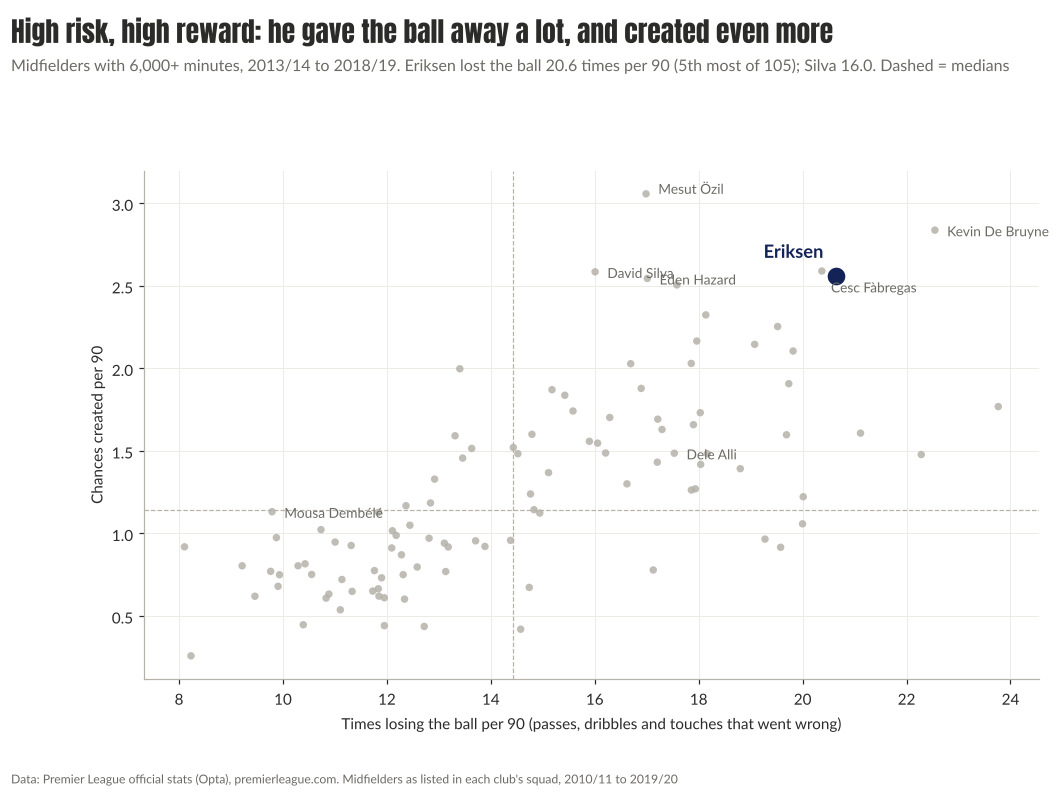

In [6]:
# Figure 9: risk and reward
fig, ax = plt.subplots(figsize=fs((10.5, 6), (9, 5.6)))
o = T.drop([ERIKSEN]); ax.scatter(o.loss90, o.cc90, s=24, color=GREY, alpha=0.85, edgecolors="none")
ax.scatter(r.loss90, r.cc90, s=170, color=NAVY, edgecolors=BG, lw=1.5, zorder=3)
ax.annotate("Eriksen", (r.loss90, r.cc90), xytext=(-8, 12), textcoords="offset points", ha="right", color=NAVY, fontsize=12, fontweight="bold")
for n, (dx, dy) in {"David Silva": (8, -4), "Mesut Özil": (8, 0), "Kevin De Bruyne": (8, -4), "Eden Hazard": (8, -4), "Cesc Fàbregas": (6, -14),
                    "Mousa Dembélé": (8, -4), "Dele Alli": (8, -4)}.items():
    if n in T.index:
        ax.annotate(n, (T.loc[n].loss90, T.loc[n].cc90), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=MUTED)
ax.axvline(T.loss90.median(), color=GREY, lw=0.8, ls="--"); ax.axhline(T.cc90.median(), color=GREY, lw=0.8, ls="--")
ax.set_xlabel("Times losing the ball per 90 (passes, dribbles and touches that went wrong)"); ax.set_ylabel("Chances created per 90")
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
rk = int(T.loss90.rank(ascending=False)[ERIKSEN])
titles(fig, "High risk, high reward: he gave the ball away a lot, and created even more",
       f"Midfielders with 6,000+ minutes, 2013/14 to 2018/19. Eriksen lost the ball {r.loss90:.1f} times per 90 ({rk}th most of {len(T)}); Silva {s.loss90:.1f}. Dashed = medians",
       SRC_PL)
fig.savefig(FIGS / "09_risk_and_reward.png")